# 01 - Explore the FD001 sensor data

**Purpose:** inspect the bundled NASA C-MAPSS data before preprocessing. No generated files are required.

Install once from the repository root: `uv sync --locked --extra notebooks`. Select the project's Python kernel, then **Restart Kernel and Run All Cells**. Paths work from the root or `notebooks/`.

Each training engine runs to failure. Test histories stop before failure; their final-cycle remaining life is supplied separately. This notebook uses raw training RUL for exploration; modelling uses the configured RUL cap.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "predictive_maintenance").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project root or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PM_PROJECT_ROOT", str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from loguru import logger
from predictive_maintenance.config import (
    EXTERNAL_DATA_DIR, RAW_DATA_DIR, INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR,
    RUL_CAP, TREND_WINDOW, SETTINGS,
)

logger.remove()
logger.add(sys.stderr, level="WARNING")
pd.set_option("display.max_columns", 40)
print(f"Project: {ROOT.name} | Python: {sys.version.split()[0]}")


Project: Predictive-Maintenance-for-Sensor-Data | Python: 3.13.9


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


## Load and inspect the source files


In [3]:
from predictive_maintenance.data.ingestion import load_cmapss, load_rul_data
from predictive_maintenance.data.preprocessing import create_rul, get_constant_columns

train = load_cmapss(EXTERNAL_DATA_DIR / "train_FD001.txt")
test = load_cmapss(EXTERNAL_DATA_DIR / "test_FD001.txt")
rul_truth = load_rul_data(EXTERNAL_DATA_DIR / "RUL_FD001.txt")
summary = pd.DataFrame({
    "split": ["train", "test"], "rows": [len(train), len(test)],
    "engines": [train.unit.nunique(), test.unit.nunique()],
    "missing_values": [train.isna().sum().sum(), test.isna().sum().sum()],
    "duplicate_keys": [train.duplicated(["unit", "cycle"]).sum(), test.duplicated(["unit", "cycle"]).sum()],
})
assert test.unit.nunique() == len(rul_truth)
display(summary)
display(train.head())


,split,rows,engines,missing_values,duplicate_keys
0,train,20631,100,0,0
1,test,13096,100,0,0


,unit,cycle,os_1,os_2,os_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Training lifetimes and raw remaining useful life


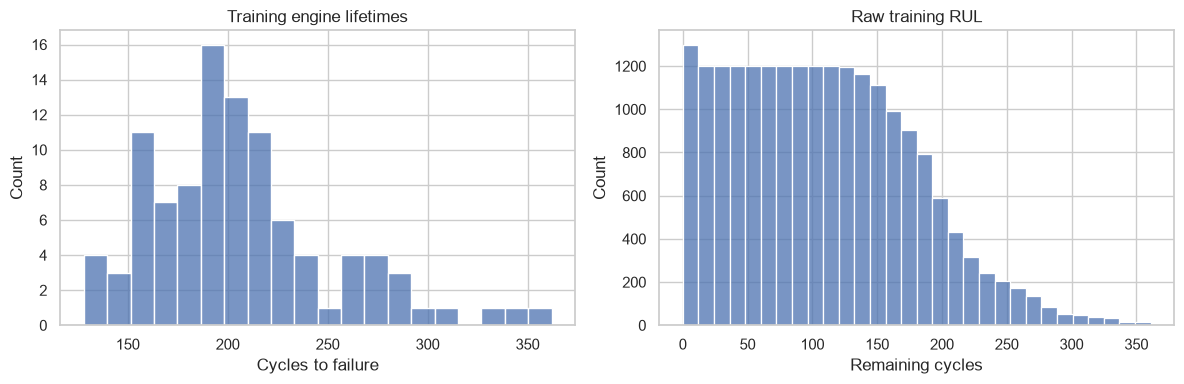

,lifetime_cycles
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


In [4]:
train = create_rul(train, cap=None)
lifetimes = train.groupby("unit").cycle.max()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(lifetimes, bins=20, ax=axes[0])
axes[0].set(title="Training engine lifetimes", xlabel="Cycles to failure")
sns.histplot(train.RUL, bins=30, ax=axes[1])
axes[1].set(title="Raw training RUL", xlabel="Remaining cycles")
plt.tight_layout()
plt.show()
display(lifetimes.describe().to_frame("lifetime_cycles"))


## Sensor variability and operating settings

Only training data determines constant columns. Low variation and exact constancy are different; the maintained preprocessing drops exactly constant columns.


In [5]:
sensors = [column for column in train if column.startswith("sensor_")]
constant_columns = get_constant_columns(train)
useful_sensors = [column for column in sensors if column not in constant_columns]
sensor_summary = pd.DataFrame({"std": train[sensors].std(), "unique_values": train[sensors].nunique()})
display(sensor_summary.sort_values("std"))
display(train[["os_1", "os_2", "os_3"]].describe())
print("Dropped by training preprocessing:", constant_columns)


,std,unique_values
sensor_1,0.000000e+00,1
sensor_10,0.000000e+00,1
sensor_19,0.000000e+00,1
sensor_18,0.000000e+00,1
sensor_16,1.387812e-17,1
sensor_5,1.776400e-15,1
sensor_6,1.388985e-03,2
sensor_15,3.750504e-02,1918
sensor_8,7.098548e-02,53
sensor_13,7.191892e-02,56


,os_1,os_2,os_3
count,20631.000000,20631.000000,20631.0
mean,-0.000009,0.000002,100.0
std,0.002187,0.000293,0.0
min,-0.008700,-0.000600,100.0
25%,-0.001500,-0.000200,100.0
50%,0.000000,0.000000,100.0
75%,0.001500,0.000300,100.0
max,0.008700,0.000600,100.0


Dropped by training preprocessing: ['os_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


## Sensor trajectories within engines


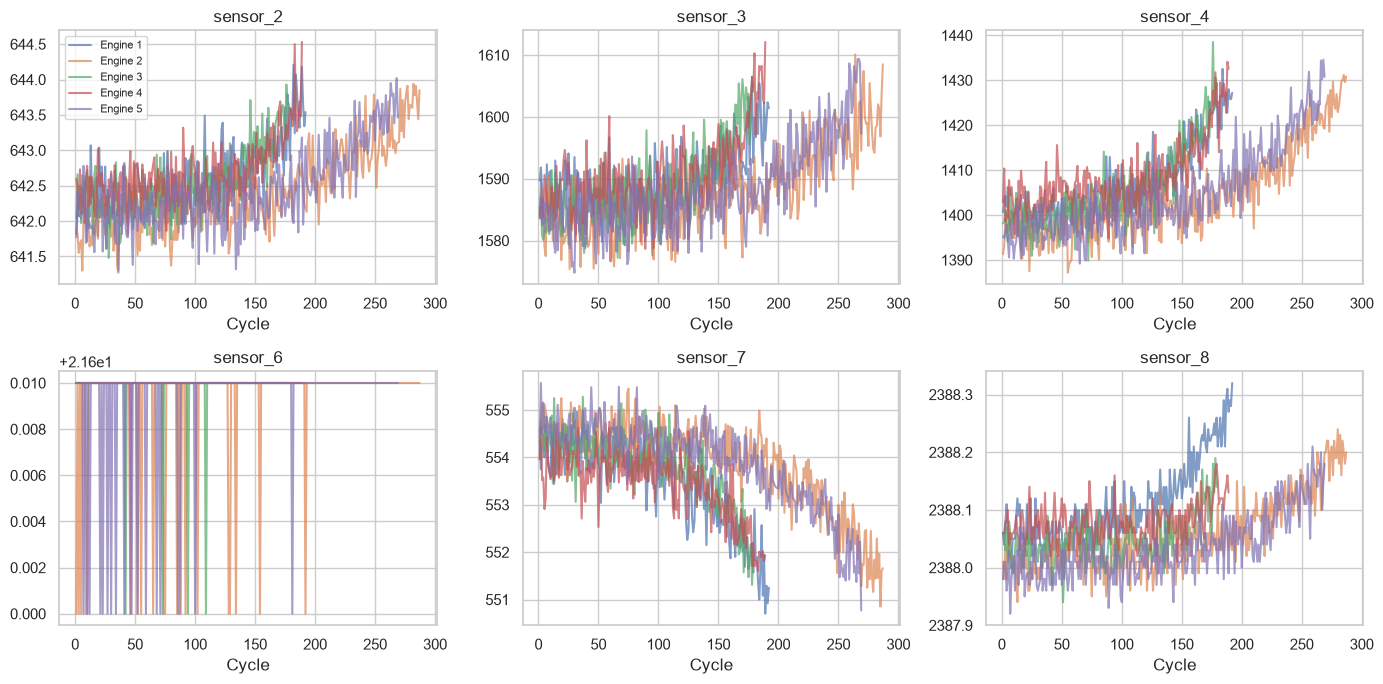

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, sensor in zip(axes.flat, useful_sensors[:6]):
    for unit in sorted(train.unit.unique())[:5]:
        history = train.loc[train.unit == unit].sort_values("cycle")
        ax.plot(history.cycle, history[sensor], alpha=0.7, label=f"Engine {unit}")
    ax.set(title=sensor, xlabel="Cycle")
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


## Correlation and degradation signals

These correlations are descriptive; they do not establish causal sensor relationships or justify selecting a model on test results.


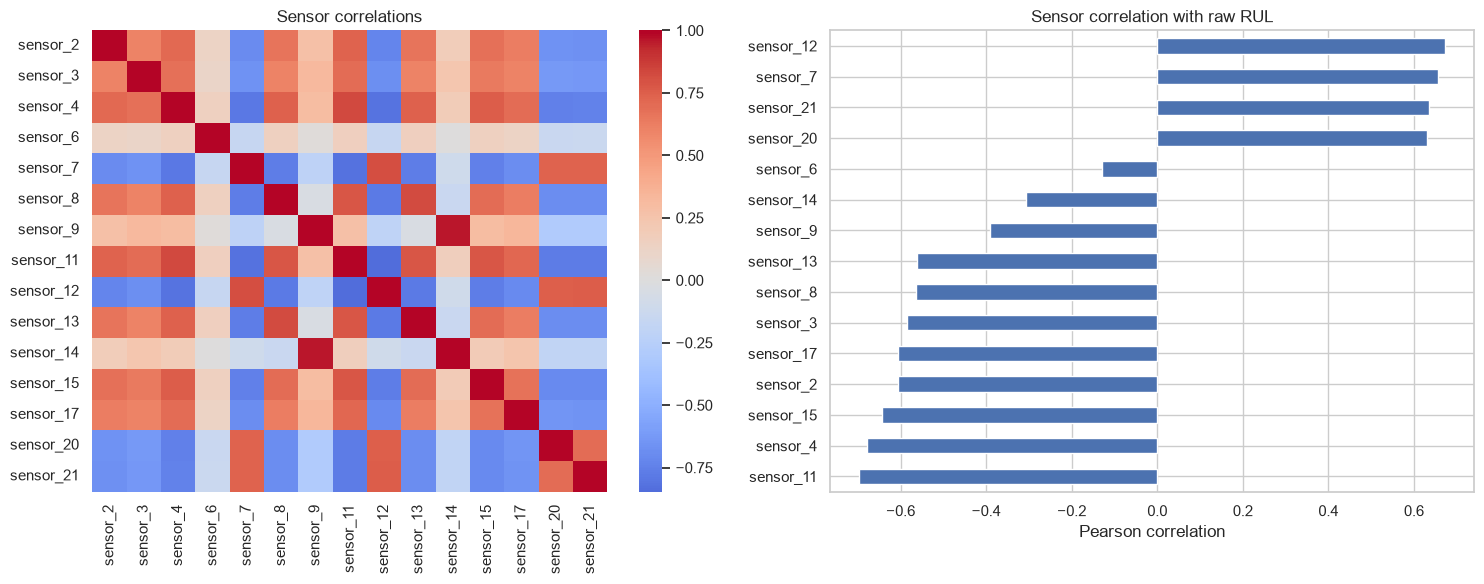

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(train[useful_sensors].corr(), cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Sensor correlations")
rul_correlation = train[useful_sensors + ["RUL"]].corr()["RUL"].drop("RUL")
rul_correlation.sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Sensor correlation with raw RUL", xlabel="Pearson correlation")
plt.tight_layout()
plt.show()


**Next:** run `02_data_cleaning.ipynb` to produce validated training and test data with consistent capped targets.
